## P2. MRI - Visualization & Segmentation of brain images

In this practical session ...

Dowload the data from the virtual campus and store it in your computer. Then, upload the data into the Colab session using the left menu.  

Remember to create a **copy** of this file in your drive and rename it to be able to edit.  

NOTES:
* If you need to review some Python basics, you can use [this tutorial](https://colab.research.google.com/drive/1lrI9l-zQf28swxkJ9dI1iBTNMlVVXqCj?usp=sharing).
* If you want to learn more about [nilearn](https://https://nilearn.github.io/stable/index.html#) and [nibabel](https://nipy.org/nibabel/), check the online documentation.  
* At the end of the session, download the .ipynb file and submit it to the Virtual Campus. Remember to write your name(s) in the filename!

In [2]:
# Check and install the toolboxes
try:
    import nibabel
except ImportError:
    # if not, install it using pip
    !pip install nibabel

# And nilearn
try:
    import nilearn
except ImportError:
    # if not, install it using pip
    !pip install nilearn

# And nilearn
try:
    import nipype
except ImportError:
    # if not, install it using pip
    !pip install nipype

## 1. Interacting with images

We will see some tools for visualization of MR images (here, brain scans)

In [3]:
import nibabel as nib
import nilearn
from nilearn import plotting

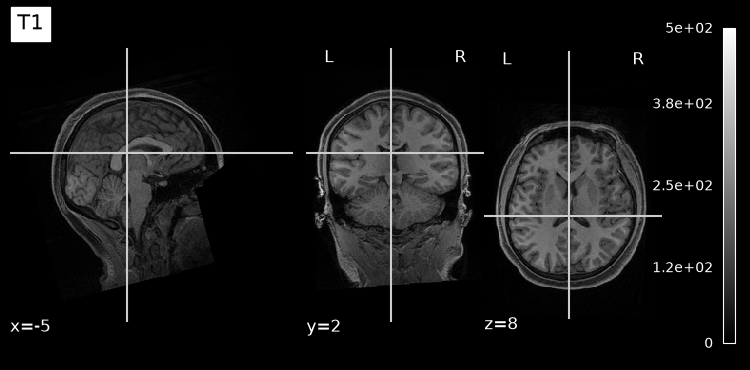

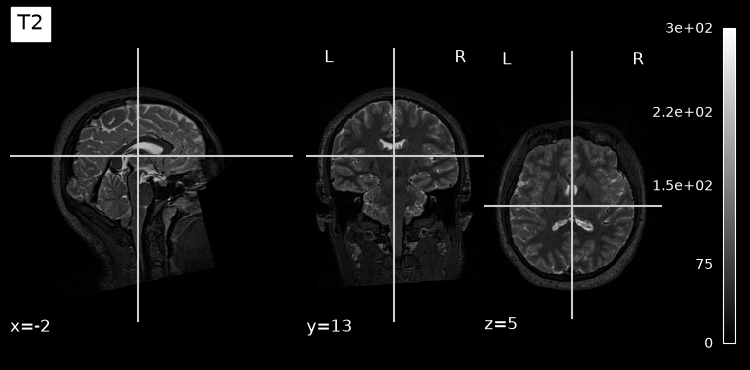

In [4]:
T1_filename = 'data_MHEDAS_MI_P1/example_T1w.nii.gz' # The name of the image file that we want to plot
T2_filename = 'data_MHEDAS_MI_P1/example_T2w.nii.gz'
T1_img = nib.load (T1_filename)
T2_img = nib.load (T2_filename)

# need to grab data arrays
T1_data = T1_img.get_fdata()
T2_data = T2_img.get_fdata()

# plot
plotting.plot_anat(T1_filename, title="T1", vmax=500)
plotting.plot_anat(T2_filename, title="T2", vmax=300)

**Exercise:** Look at the images and descibe the visual differences between the two types of images (2-5 lines).

T1- and T2-weighted MRI images show differences in signal intensity between tissues. For example, cerebrospinal fluid appears dark in T1-weighted images but bright in T2-weighted images. 
These differences arise because T1 and T2 represent different relaxation processes: T1 describes the recovery of longitudinal magnetization, whereas T2 describes the decay of transverse magnetization.

##2. Artifact correction and clean-up



*   Correcting artifacts and cleaning the image is crucial for the success of **automated processing methods** (i.e., segmentation, registration, ...)
*   A typical issue with MRI scans is caused by **spatial inhomogeneties** of the magnetic field, namely **bias field**, a smooth signal intensity variation within tissue of the same physical properties.
*   Note that **bias field** is modeled as a multiplicative factor, whereas ***noise*** is assumed to be an additive and spatially independent (Gaussian) factor.


In the fibure below you have an example of a T1w image and its bias.







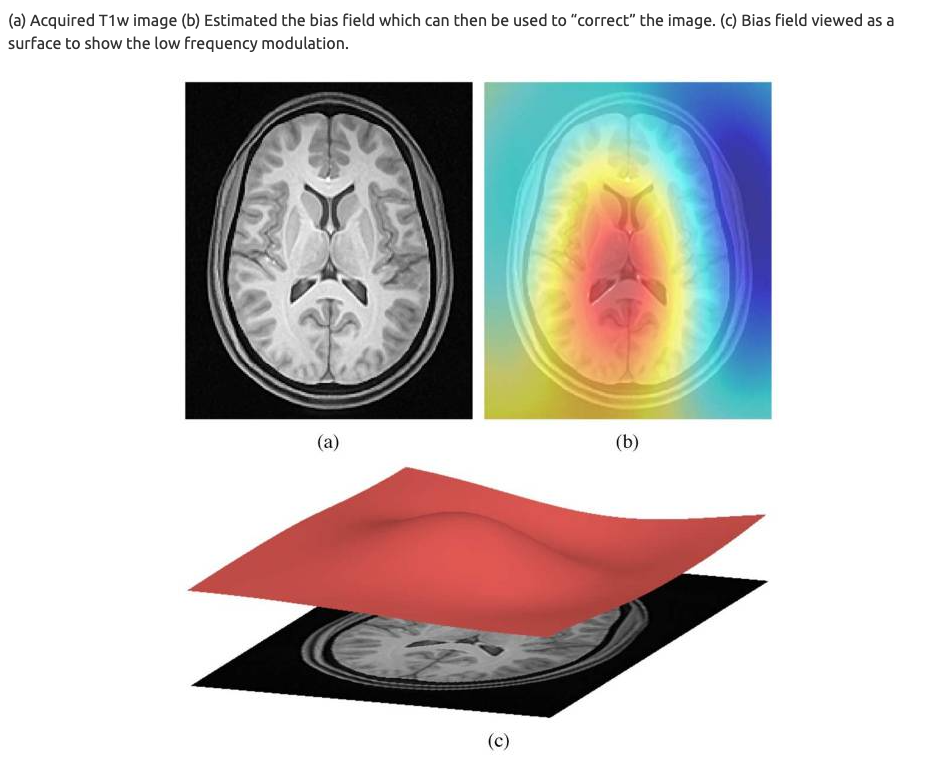

###Bias field correction
There are many automated pipelines that can be used to perform this corrections (some are integrated within longer pipelines such as FreeSurfer, FSL and SPM).

In this example, we will *simulate* the use of the ANTs software. It can be run independently (see [documentation](https://http://stnava.github.io/ANTs/)) or within the nipype package.



```
from nipype.interfaces.ants import N4BiasFieldCorrection

n4 = N4BiasFieldCorrection()
n4.inputs.dimension = 3
n4.inputs.input_image = 'example_T1w.nii.gz'
n4.inputs.bspline_fitting_distance = 300
n4.inputs.shrink_factor = 3
n4.inputs.n_iterations = [50,50,30,20]
n4.cmdline

```


The above code would give an instruction that should be run from command line (note that this could be executed from a terminal, YOU DON'T HAVE TO RUN IT FOR THIS PRACTICAL SESSION).

The ***bias field correction*** produces changes in the histogram and can have a strong impact on a subsequant segmentation task.  

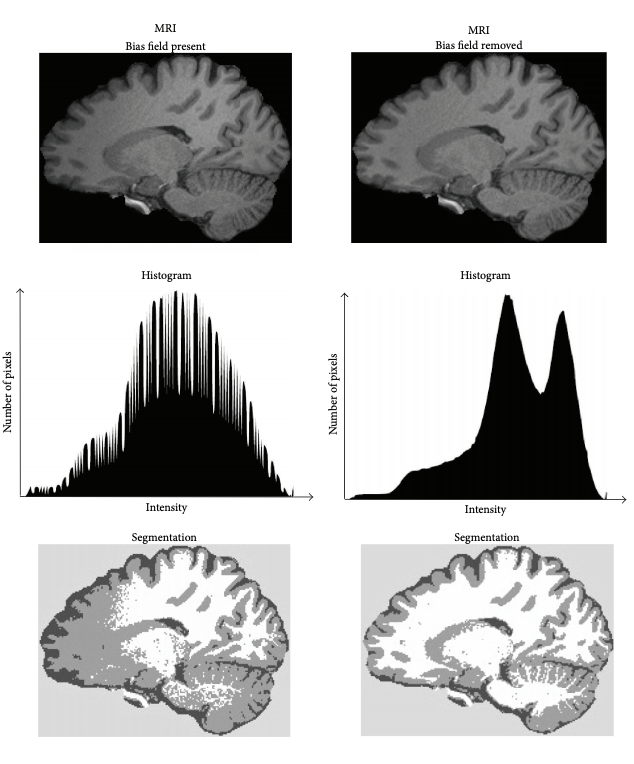

###Visualizing images before and after correction
We'll use nibabel/nilearn tools to visualize some of the example images.  

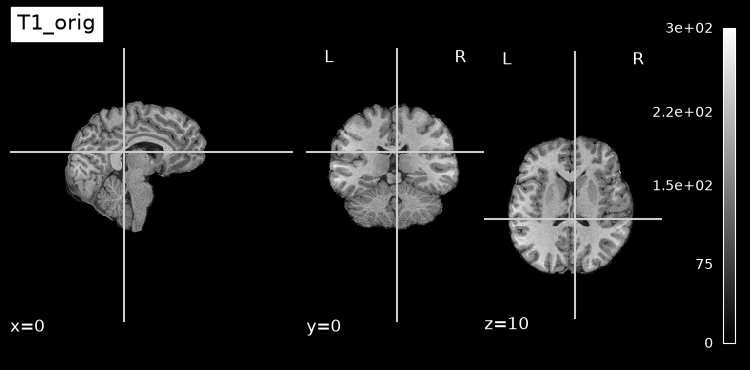

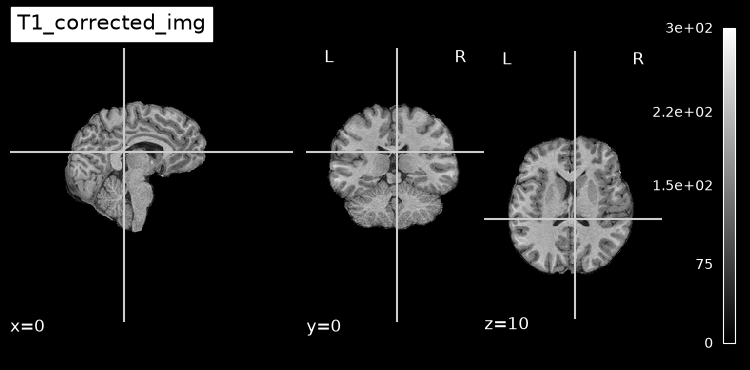

In [5]:
import nibabel as nib
from nilearn import plotting
T1_orig = 'data_MHEDAS_MI_P1/example_T1_brain.nii.gz'
T1_corrected = 'data_MHEDAS_MI_P1/example_T1_brain_restore.nii.gz' # this is the bias corrected image :)
T1_img_orig = nib.load(T1_orig)
T1_img_corrected = nib.load(T1_corrected)

# plot
cut_coords = (0,0,10) # try changing these coordinates
plotting.plot_anat(T1_orig, title="T1_orig", cut_coords=cut_coords, vmax=300)
plotting.plot_anat(T1_corrected, title="T1_corrected_img", cut_coords=cut_coords, vmax=300)

**Exercise:** Describe the differences that you see between the images above? Try changing the plotting arguments to make them more visible.    

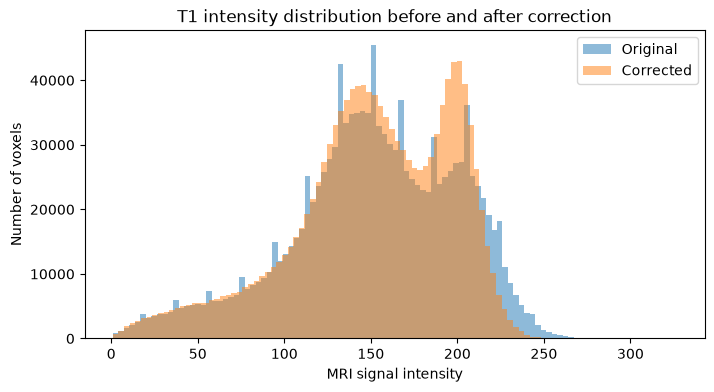

In [6]:
import numpy as np
import matplotlib.pyplot as plt

original_data = T1_img_orig.get_fdata() # grab the data array from the nibabel object
corrected_data = T1_img_corrected.get_fdata()

# Select brain-related voxels using a mask from the original image
mask = np.isfinite(original_data) & (original_data > 0) & np.isfinite(corrected_data)

plt.figure(figsize=(8, 4))

plt.hist(original_data[mask], bins=100, alpha=0.5, label="Original")
plt.hist(corrected_data[mask], bins=100, alpha=0.5, label="Corrected")

plt.xlabel("MRI signal intensity")
plt.ylabel("Number of voxels")
plt.title("T1 intensity distribution before and after correction")
plt.legend()
plt.show()

In [8]:
# Calculate the difference
difference = corrected_data - original_data

# Summarize the changes
print("Mean absolute difference:", np.mean(np.abs(difference)))
print("Maximum absolute difference:", np.max(np.abs(difference)))

Mean absolute difference: 0.8581536278412407
Maximum absolute difference: 41.592193603515625


**Exercise:** Plot the bias field image (Find it in your data folder!)

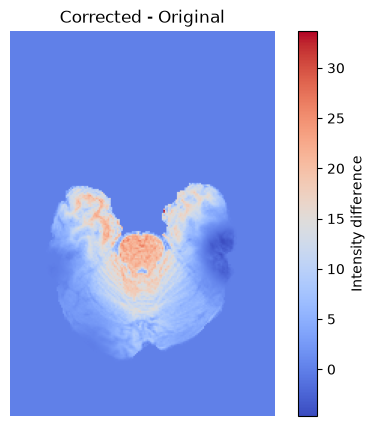

In [9]:
slice_idx = original_data.shape[2] // 2

plt.figure(figsize=(6, 5))
plt.imshow(difference[:, :, slice_idx].T, cmap="coolwarm", origin="lower")
plt.colorbar(label="Intensity difference")
plt.title("Corrected - Original")
plt.axis("off")
plt.show()

**Exercise:** In your owns words, explain what is bias and how it affects images.

##3. Brain extraction

A common preprocessing step in brain MRI is to extract the brain (separate the brain from skull, skin, neck,...)


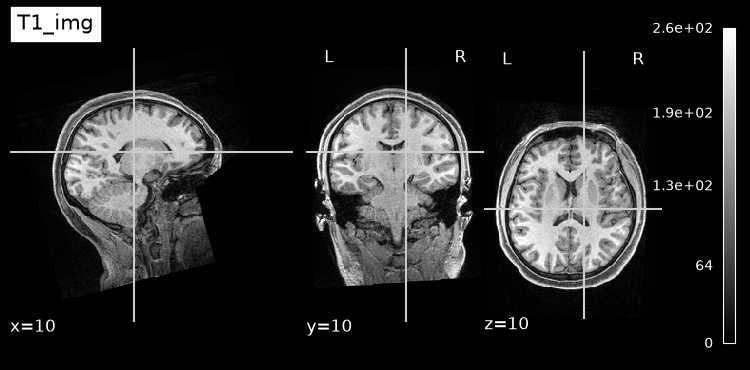

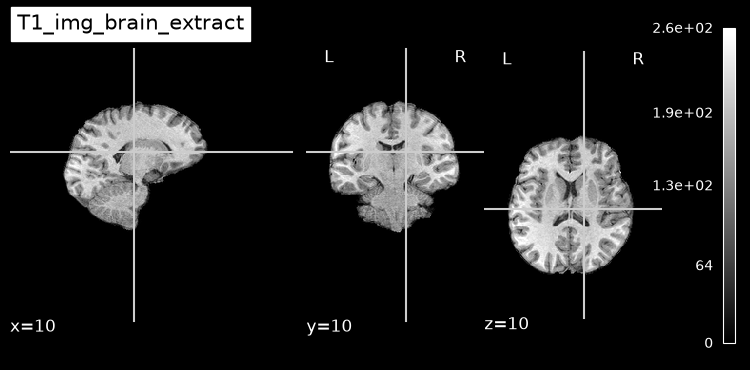

In [10]:
from nipype.interfaces.ants.segmentation import BrainExtraction
T1_img = 'data_MHEDAS_MI_P1/example_T1w.nii.gz'
T1_brain_extract = 'data_MHEDAS_MI_P1/example_T1_brain.nii.gz'
T1_img = nib.load(T1_img)
T1_img_brain_extract = nib.load(T1_brain_extract)

# plot
cut_coords = (10,10,10)
plotting.plot_anat(T1_img, title="T1_img", cut_coords=cut_coords, vmax=255)
plotting.plot_anat(T1_img_brain_extract, title="T1_img_brain_extract", cut_coords=cut_coords, vmax=255)


**Exercise:** Based on the previous images, what do the brain extraction tools do?

Brain extractions


##4. Brain Segmentation
A common preprocessing step that separates the main brain tissues using the histogram.
There are many available tools to do this, for example FSL, FreeSurfer or SPM.

Here, we will explore the outputs of a basic tissue segmentation.

In [12]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Text(0.5, 1.0, 'T1 data before skull-stripping')

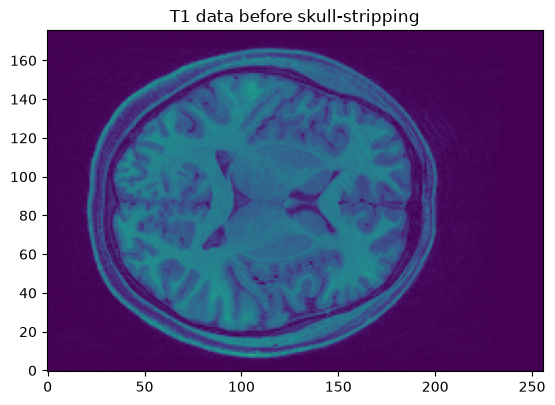

In [15]:
# use imshow to plot the figures
# Plot first figure
T1_img = 'data_MHEDAS_MI_P1/example_T1w.nii.gz'
T1_img = nib.load(T1_img)
T1_data = T1_img.get_fdata()
plt.imshow(T1_data[:, :, 160], vmax=500, origin="lower")
plt.title('T1 data before skull-stripping')

Now, we can compute the histogram of this image:

(0.0, 255.0)

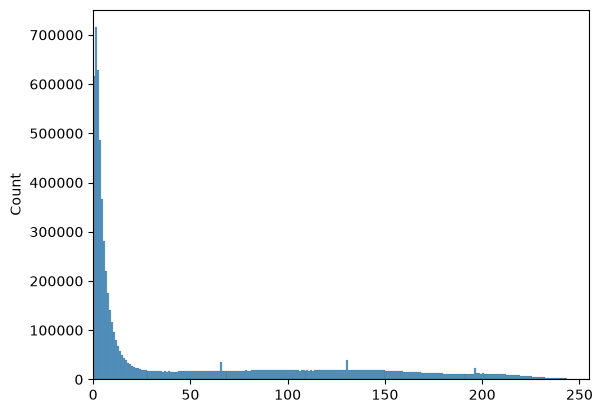

In [16]:

# Compute the optimal bin size according to the data
bins = np.histogram_bin_edges(T1_data[T1_data!= 0], bins='auto')
# Plot the histogram
sns.histplot(T1_data[T1_data != 0], bins=bins)
plt.xlim([0, 255])

**Question:** What do you observe from the previous histogram?

**Exercise:** plot the image and the histogram after skull stripping (find it in your folder). Try also examining other slices and sections.

Text(0.5, 1.0, 'T1 data after skull-stripping')

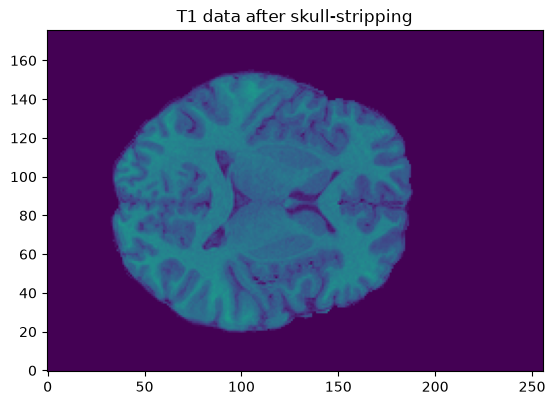

In [18]:
# place your code here (image):
T1_img = 'data_MHEDAS_MI_P1/example_T1_brain.nii.gz'
T1_img = nib.load(T1_img)
T1_data = T1_img.get_fdata()
plt.imshow(T1_data[:, :, 160], vmax=500, origin="lower")
plt.title('T1 data after skull-stripping')

(0.0, 255.0)

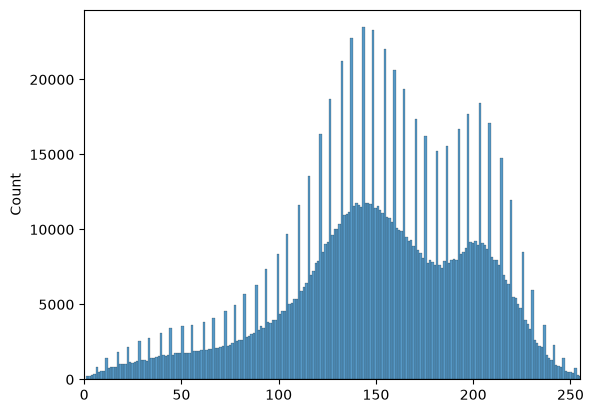

In [19]:
# place your code here (histogram)
# Compute the optimal bin size according to the data
bins = np.histogram_bin_edges(T1_data[T1_data!= 0], bins='auto')
# Plot the histogram
sns.histplot(T1_data[T1_data != 0], bins=bins)
plt.xlim([0, 255])

Now, we will examine the outputs of the segmentation together with the  histogram. Note that we have computed the segmentation before and we give the output to you:

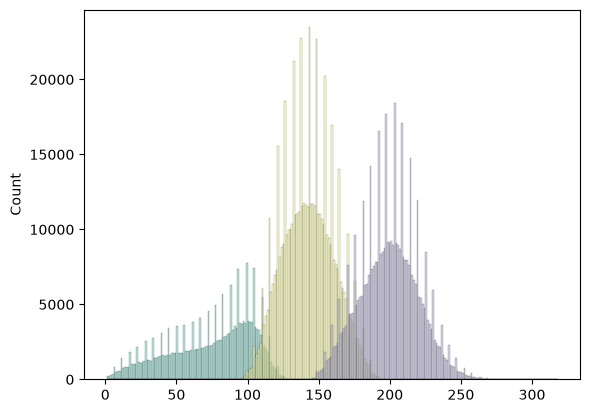

In [21]:
# NOTE: brain data is stored into 'T1_brain_data'

import itertools
T1_brain_img = 'data_MHEDAS_MI_P1/example_T1_brain.nii.gz'
T1_brain_img = nib.load(T1_brain_img)
T1_brain_data = T1_img.get_fdata()
T1_seg_image = 'data_MHEDAS_MI_P1/example_T1_brain_seg.nii.gz'
T1_seg_image = nib.load(T1_seg_image)
T1_seg_data = T1_seg_image.get_fdata()
labels = np.unique(T1_seg_data[T1_seg_data != 0]).astype('int')
palette = itertools.cycle(sns.color_palette("Set3"))
for label in labels:
    sns.histplot(T1_brain_data[T1_seg_data == label], bins=bins, color=next(palette), alpha=0.6)

**Exercise**: Use the histogram code given above to explore the differences of performing segmentation on images before/after bias correction.  

In [ ]:
# place your code here

Final remarks: A question of probability:

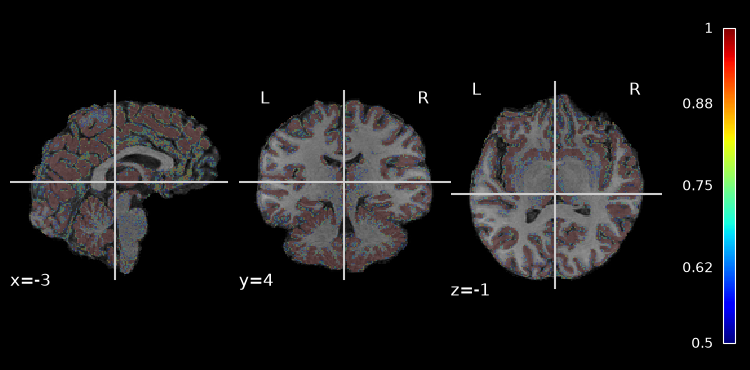

In [22]:

GMprob_image = 'data_MHEDAS_MI_P1/example_T1_brain_pve_1.nii.gz'
GMprob_image = nib.load(GMprob_image)
GM_probmap = GMprob_image.get_fdata()

plotting.plot_roi(roi_img=GMprob_image, bg_img=T1_img, alpha=0.2, cmap="jet", vmin=0.5, vmax=1);

**Exercise**: Try different options of the plotting.plot_roi function to improve the image above.

In [ ]:
# place your code here